In [2]:
import numpy as np
import pandas as pd 
import os

In [6]:
df=pd.read_csv("drug200.csv")

In [7]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [8]:
df=pd.get_dummies(df,columns=["Sex","BP","Cholesterol"],drop_first=True)

In [9]:
df.head()

,Age,Na_to_K,Drug,Sex_M,BP_LOW,BP_NORMAL,Cholesterol_NORMAL
0,23,25.355,drugY,False,False,False,False
1,47,13.093,drugC,True,True,False,False
2,47,10.114,drugC,True,True,False,False
3,28,7.798,drugX,False,False,True,False
4,61,18.043,drugY,False,True,False,False


In [10]:
y=df['Drug']
x=df.drop("Drug",axis=1)

In [28]:
y = df['Drug']
X = df.drop("Drug", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tree = DecisionTreeClassifier()
model = tree.fit(X_train, y_train)

model.score(X_test, y_test)

0.975

In [29]:
model.predict([[33,22.200,True,True,False,True]])

c:\Users\i-bhakti.patel\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array(['drugY'], dtype=object)

In [30]:
import pandas as pd

new_patient = pd.DataFrame(
    [[33, 22.2, True, True, False, True]],
    columns=X.columns
)

prediction = model.predict(new_patient)

print(prediction)

['drugY']


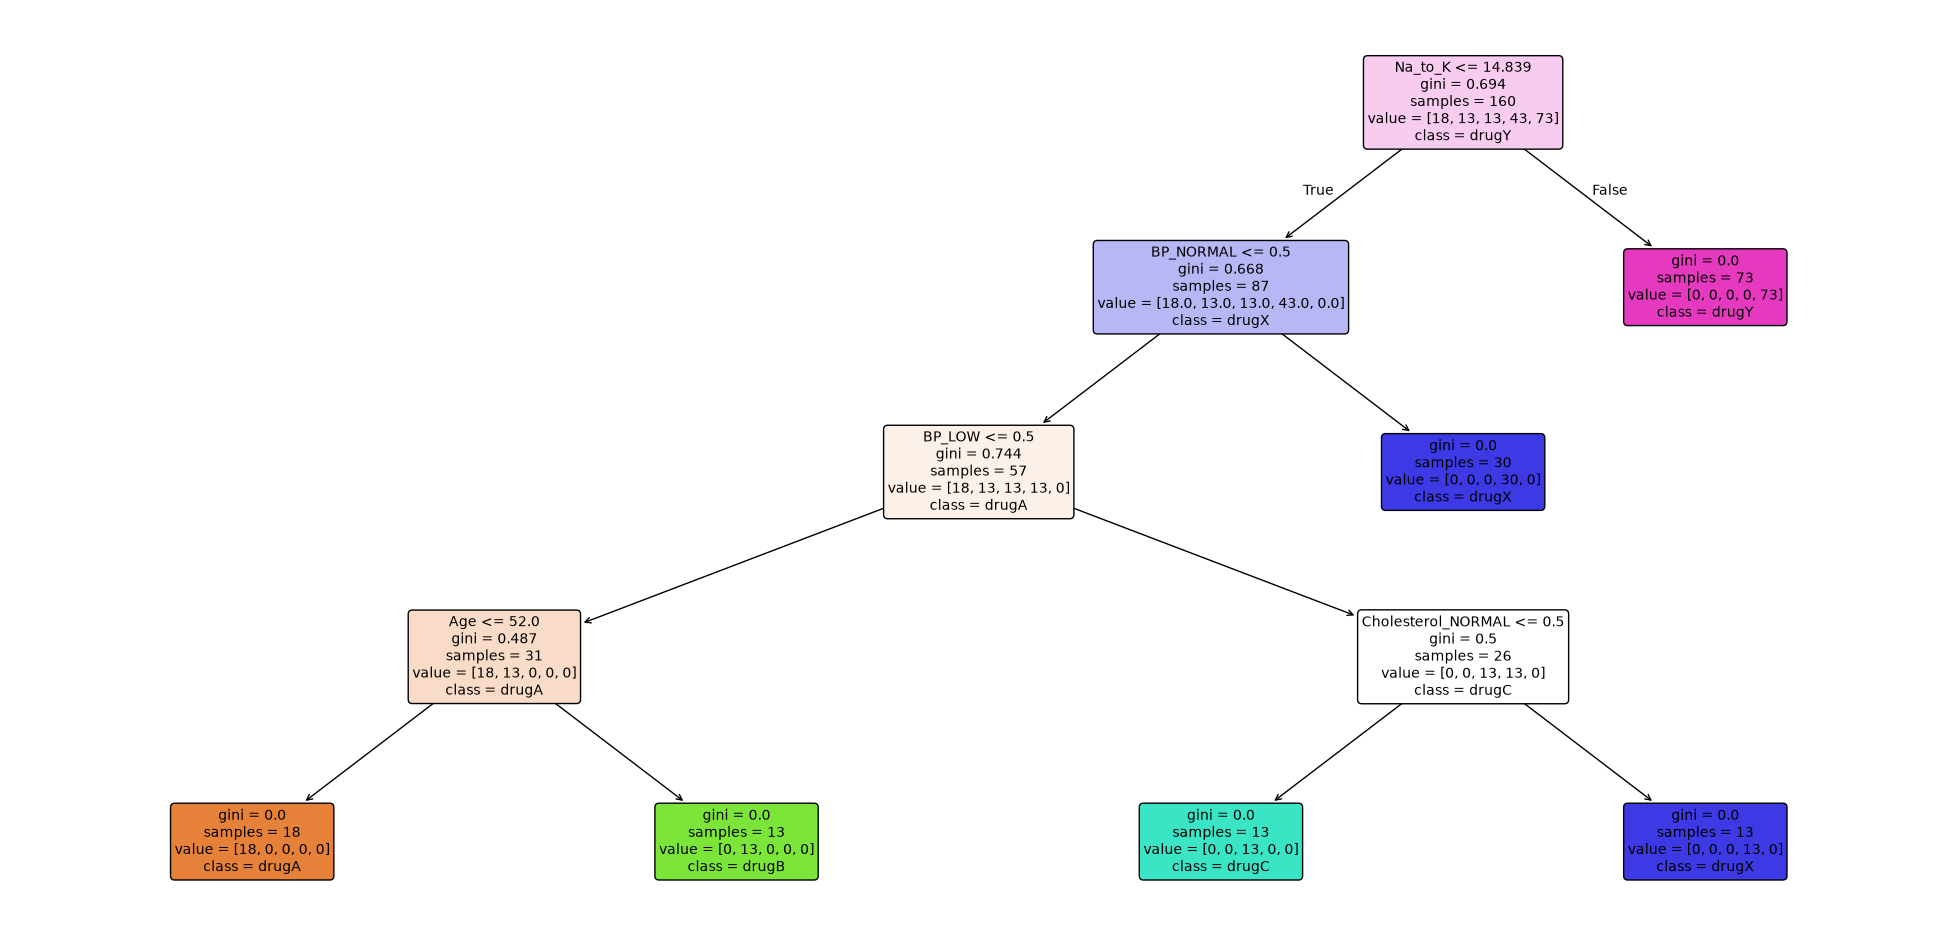

In [31]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()